# Plotting Parametrizations for Comparison Figure

In [1]:
import sys
sys.path.append('../../')

import jax.numpy as jnp
import utils.petrophysics_capillaryBundles as petro_cap
import utils.parameter_interpolation as inter
from utils import plotting_utils

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


In [2]:
param = "cap" # "imp10" "imp50" "drying" "drying_omega10" "cap"
interp_folder = "../../input/interpolation/"
interp_filename = f"interpolation_{param}.pkl"

### Setting van Genuchten parameters

In [3]:
soil = jnp.ones((40,400))  # soil type array

# # Sandy soil parameters
soil_type = {1:{}, 2:{}}
soil_type[1]["alpha"] = 14.5                        # van Genuchten alpha [1/m]
soil_type[1]["Ksat"] = 8.25e-5                      # saturated hydraulic conductivity [m/s]
soil_type[1]["N"] = 2.68                            # van Genuchten N [-]
soil_type[1]["Theta_r"] = 0.045                     # minimum volumetric water content [-]
soil_type[1]["Theta_s"] = 0.43                      # maximum volumetric water content [-]

# # Loamy soil parameters
soil_type[2]["alpha"] = 1.6
soil_type[2]["Ksat"] = 6.94e-7
soil_type[2]["N"] = 1.37
soil_type[2]["Theta_r"] = 0.034
soil_type[2]["Theta_s"] = 0.46

### Defining Se and T arrays along which the interpolation is done

In [4]:
Se = jnp.linspace(1e-6,1,int(5e4)) # effective saturation [-]
#   discretize T
T = jnp.append(jnp.append(jnp.append(jnp.arange(-30,-5,1),jnp.arange(-5,-1,1e-2)),jnp.arange(-1,0,1e-3)),jnp.array([0,10])) # interpolate krel and theta_l for each soil type
#soil_type = inter.interpolate_parameter_drying(Se, T, soil_type, filename=interp_folder+interp_filename_drying, method='monotonic', extrapolate=True)
soil_type = inter.interpolate_parameter(Se, T, soil_type, filename=interp_folder+interp_filename, parametrization=param, method='monotonic', extrapolate=True)

del T,Se

Loaded interpolated soil type from file:  ../../input/interpolation/interpolation_cap.pkl


In [5]:
# Arrays for plotting 
Se = jnp.linspace(1e-6,1,1000)
hc = petro_cap.h_from_S(Se, soil_type[1]["alpha"], soil_type[1]["N"])
T = jnp.linspace(-10,10,10000)

/home/anne/Dokumente/Promotion/Code/CryoRich_AD/notebooks/creating_figures/../../utils/plotting_utils.py:701: RuntimeWarning: divide by zero encountered in log10
  ax.plot_surface(np.log10(X), Y, Z, cmap="Blues")
/home/anne/Dokumente/Promotion/Code/CryoRich_AD/notebooks/creating_figures/../../utils/plotting_utils.py:716: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


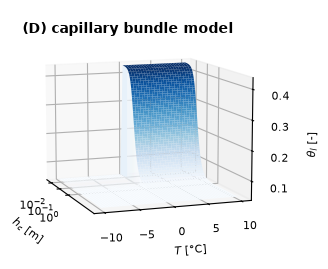

In [6]:
# Plot of liquid watercontent
fig, ax = plotting_utils.plot_theta_l_surface(soil_type, param, hc, T, n_per_row=2)
fig.savefig(f"../../figures/theory/theta_l_{param}.pdf", dpi=600, bbox_inches='tight', pad_inches=0.25)

/home/anne/Dokumente/Promotion/Code/CryoRich_AD/notebooks/creating_figures/../../utils/plotting_utils.py:679: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


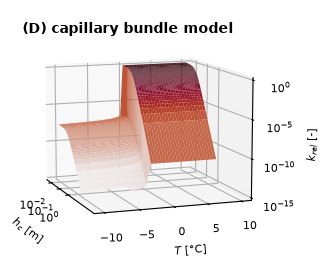

In [ ]:
# plot of k_rel
fig, ax = plotting_utils.plot_krel_surface(soil_type, param, hc, T, n_per_row=2)
fig.savefig(f"../../figures/theory/k_rel_{param}.png", dpi=600, bbox_inches='tight', pad_inches=0.25)